# PerfuSense AI · Lesson 5: pre-training on synthetic bodies

Real pressure data is scarce. Computers can simulate it: BodyPressureSD drops 3D bodies onto a simulated mattress and calculates the pressure map. The plan is **transfer learning**:

1. **Pre-train** on many cheap synthetic maps.
2. **Fine-tune** on the few real maps, starting from those weights instead of from random numbers.

Does it help? We test it honestly, and the key question is: **how much real data do you need, with and without pre-training?** That matters for us, because we will record only a few people on our own mat.

We downloaded a small part: 6 files, 12,381 synthetic maps (the whole set has 97,495).

> Research prototype, not a medical device. **Licence:** BodyPressureSD is for non-commercial academic or non-profit research only (CC BY-SA 4.0 plus its agreement). Cite Clever et al., TPAMI 2023. The data stays out of git.

In [1]:
import sys
import inspect
import time

sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.linear_model import LogisticRegression

from perfusense_ai import data as D
from perfusense_ai import model as M


def show(*functions):
    """Print the real source code of our shared functions."""
    for f in functions:
        print(inspect.getsource(f))

## Step 1 · Opening files from the internet safely

These files are Python **pickle** files. A pickle can run any code the moment you open it. A normal `pickle.load()` on a downloaded file means trusting whoever made it. We load them with a guard that only allows NumPy arrays, and stops if anything else appears.

In [2]:
show(D.NumpyOnlyUnpickler, D.load_bodypressure)

frames, labels = D.load_bodypressure()
print("synthetic maps:", frames.shape, "| value range:", frames.min(), "to", frames.max())
print("per class:", dict(zip(D.CLASSES, np.bincount(labels))))

class NumpyOnlyUnpickler(pickle.Unpickler):
    """Pickle files can run code when opened. This loader refuses everything except NumPy arrays."""
    ALLOWED = {("numpy.core.multiarray", "_reconstruct"), ("numpy._core.multiarray", "_reconstruct"),
               ("numpy.core.multiarray", "scalar"), ("numpy._core.multiarray", "scalar"),
               ("numpy", "ndarray"), ("numpy", "dtype")}

    def find_class(self, module, name):
        if (module, name) not in self.ALLOWED:
            raise pickle.UnpicklingError(f"blocked {module}.{name}")
        return super().find_class(module.replace("numpy.core", "numpy._core"), name)

def load_bodypressure(mirror=False):
    """Synthetic maps -> frames (n, 64, 27) and class index (n,). The file name gives the posture."""
    names = {"lay": "supine", "lside": "left", "rside": "right"}
    frames, labels = [], []
    for path in sorted((data_root() / "BodyPressureSD" / "synth").glob("train_slp_*.p")):
        with open(path, "rb") as f:
     

synthetic maps: (12381, 64, 27) | value range: 0.0 to 101.0
per class: {'supine': np.int64(4372), 'left': np.int64(4060), 'right': np.int64(3949)}


The map is 64×27, the same grid as PoPu. Each file's name gives the posture (`lay`, `lside`, `rside`), so the labels are free.

## Step 2 · Is it mirrored too?

Lesson 2 taught us never to trust the word "left". Same test: train a simple model on the synthetic maps, test it on real people, with and without flipping the columns.

In [3]:
t0 = time.time()
recordings = D.load_pmd() + [r for r in D.load_popu() if r["label"] != "prone"]
print(f"{len(recordings)} real recordings in {time.time() - t0:.0f} s")
X_bed, y_bed, people_bed = D.windows_from_recordings(recordings, D.whole_bed_view)

def per_frame_scale(small):
    return np.stack([D.normalise_window(f) for f in small])

synth_bed = per_frame_scale(D.area_resize(D.pad_to_width(frames)))

def flat(x):
    return x.reshape(len(x), -1)

real_flat = flat(X_bed.mean(axis=1))
as_stored = LogisticRegression(max_iter=3000, class_weight="balanced").fit(flat(synth_bed), labels)
mirrored = LogisticRegression(max_iter=3000, class_weight="balanced").fit(flat(synth_bed[:, :, ::-1]), labels)
print("synthetic as stored -> real people:", M.score(y_bed, as_stored.predict(real_flat)))
print("synthetic mirrored  -> real people:", M.score(y_bed, mirrored.predict(real_flat)))

1481 real recordings in 28 s


synthetic as stored -> real people: {'balanced_acc': 0.344, 'macro_f1': 0.269}
synthetic mirrored  -> real people: {'balanced_acc': 0.557, 'macro_f1': 0.561}


The same story as PoPu: as stored the score is 34.4 %, which is guessing. Flipped, it reaches 55.7 %. So the synthetic data is mirrored compared with our training view, and we flip it. PoPu and the synthetic data agree with each other, which suggests PmatData is the odd one out (see Lesson 2).

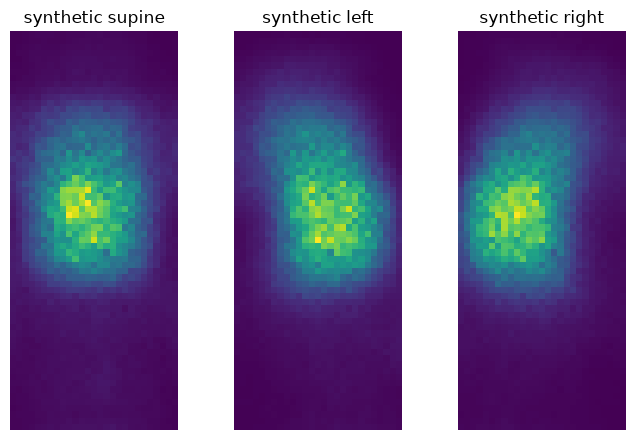

In [4]:
MIRROR_SYNTH = True    # decided by the test above

synth = frames[:, :, ::-1] if MIRROR_SYNTH else frames
del frames, synth_bed

fig, axes = plt.subplots(1, 3, figsize=(7, 4.5))
for ax, i, name in zip(axes, range(3), D.CLASSES):
    ax.imshow(synth[labels == i].mean(axis=0)); ax.set_title(f"synthetic {name}"); ax.axis("off")
plt.tight_layout(); plt.show()

## Step 3 · Make synthetic windows that look like our mat

Two gaps to close:

- **Patch.** A synthetic body has no "person" with a supine reference, so we set one fixed mat position from the average supine map and move it by up to 2 sensors for each map. That also imitates placement error.
- **Time.** A synthetic map is a single frame, but the Transformer reads 30. We repeat the frame 30 times with 2 % sensor noise. It teaches *what a posture looks like*, not how people move. This is why the plan always called synthetic data pre-training only.

In [5]:
show(D.still_windows)

rng = np.random.default_rng(0)
padded = D.pad_to_width(synth)
top, left = D.sacrum_point(padded[labels == 0].mean(axis=0))
print("synthetic mat position:", (top, left))

patches = np.stack([D.crop_patch(f[None], top + rng.integers(-2, 3), left + rng.integers(-2, 3))[0] for f in padded])
del padded, synth
X_synth = D.still_windows(patches, rng)
print("synthetic windows:", X_synth.shape)

positions = D.mat_positions(recordings)
X, y, people = D.windows_from_recordings(recordings, D.patch_view(positions, jitter=2, rng=rng))
del recordings
print("real windows:", X.shape, "| people:", len(set(people)))

def still_windows(frames, rng, noise=0.02):
    """Turn single frames (n, 10, 10) into 30-frame windows: repeat each one with small sensor noise."""
    return np.stack([normalise_window(np.repeat(f[None], T, axis=0)
                                      * (1 + noise * rng.standard_normal((T,) + f.shape))) for f in frames])

synthetic mat position: (25, 10)


synthetic windows: (12381, 30, 10, 10)


real windows: (2669, 30, 10, 10) | people: 73


## Step 4 · Split the real people

A fixed test group of real people, never touched: every fourth person. Then 6 people for validation. Everyone else is the pool we draw training people from.

In [6]:
names = sorted(set(people))
test_people = names[::4]
rest = [p for p in names if p not in test_people]
val_people = list(np.random.default_rng(1).choice(rest, 6, replace=False))
pool = [p for p in rest if p not in val_people]

te, va = np.isin(people, test_people), np.isin(people, val_people)
print(f"test {len(test_people)} people, validation {len(val_people)} people, training pool {len(pool)} people")

test 19 people, validation 6 people, training pool 48 people


## Step 5 · Pre-train

Train the Transformer on synthetic windows only. Validation uses **real** people, because real data is what we care about. Save the weights: this is the "reuse the old model" idea from earlier, in practice.

In [7]:
keras.utils.set_random_seed(42)
pretrained = M.build_transformer()
t0 = time.time()
history = M.train(pretrained, X_synth, labels, X[va], y[va], epochs=30, batch_size=64, patience=5, verbose=2)
print(f"pre-training took {time.time() - t0:.0f} s")
print("synthetic only, real test people (never trained on any real map):", M.score(y[te], M.predict(pretrained, X[te])))

PRETRAINED = "../models/pretrained_synthetic.weights.h5"
import os
os.makedirs("../models", exist_ok=True)
pretrained.save_weights(PRETRAINED)
del X_synth

Epoch 1/30


194/194 - 15s - 78ms/step - accuracy: 0.4294 - loss: 1.0761 - val_accuracy: 0.4931 - val_loss: 1.0929


Epoch 2/30


194/194 - 8s - 39ms/step - accuracy: 0.4533 - loss: 1.0192 - val_accuracy: 0.5482 - val_loss: 1.0983


Epoch 3/30


194/194 - 7s - 37ms/step - accuracy: 0.4670 - loss: 1.0006 - val_accuracy: 0.5344 - val_loss: 1.0892


... (22 outputs left out)

Epoch 15/30


194/194 - 7s - 37ms/step - accuracy: 0.6509 - loss: 0.7780 - val_accuracy: 0.6556 - val_loss: 0.9948


pre-training took 117 s


synthetic only, real test people (never trained on any real map): {'balanced_acc': 0.565, 'macro_f1': 0.569}


## Step 6 · Fine-tune, and compare with starting from zero

For each amount of real training people, train twice from the **same people**:

- **from zero:** random starting weights, learning rate 0.001;
- **pre-trained:** load the saved weights, smaller learning rate 0.0003. A smaller rate because we want to adjust good weights, not destroy them.

We repeat each with 3 different random groups of people, because small groups vary a lot.

In [8]:
def run(n_people, seed, use_pretrained):
    chosen = np.random.default_rng(seed).choice(pool, n_people, replace=False)
    tr = np.isin(people, chosen)
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    m = M.build_transformer()
    if use_pretrained:
        m.load_weights(PRETRAINED)
    M.train(m, X[tr], y[tr], X[va], y[va], batch_size=32, lr=3e-4 if use_pretrained else 1e-3)
    return M.score(y[te], M.predict(m, X[te]))["balanced_acc"]

rows = []
t0 = time.time()
for n in [2, 5, 10, 20, len(pool)]:
    for seed in range(3):
        for use_pretrained in (False, True):
            rows.append({"people": n, "seed": seed, "start": "pre-trained" if use_pretrained else "from zero",
                         "balanced_acc": run(n, seed, use_pretrained)})
    print(f"{n} people done ({time.time() - t0:.0f} s)")
curve = pd.DataFrame(rows)
summary = curve.pivot_table(index="people", columns="start", values="balanced_acc", aggfunc=["mean", "std"]).round(3)
summary

2 people done (63 s)


5 people done (131 s)


10 people done (210 s)


20 people done (307 s)


48 people done (482 s)


mean                   std            
start  from zero pre-trained from zero pre-trained
people                                            
2          0.403       0.625     0.088       0.006
5          0.478       0.654     0.046       0.013
10         0.562       0.727     0.069       0.013
20         0.657       0.721     0.067       0.045
48         0.724       0.811     0.031       0.017

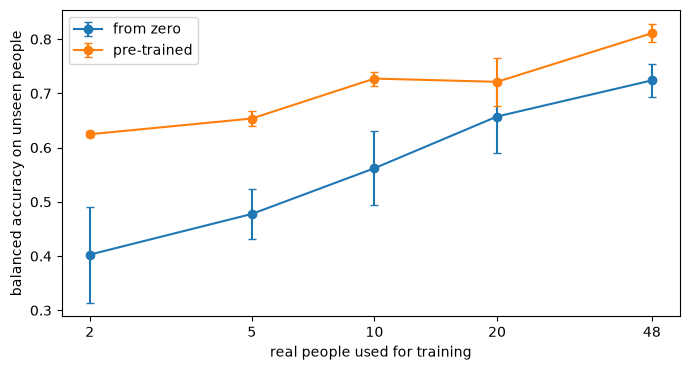

In [9]:
plt.figure(figsize=(7, 3.8))
for start, colour in [("from zero", "tab:blue"), ("pre-trained", "tab:orange")]:
    part = curve[curve.start == start].groupby("people").balanced_acc
    plt.errorbar(part.mean().index, part.mean(), yerr=part.std(), marker="o", capsize=3, color=colour, label=start)
plt.xscale("log"); plt.minorticks_off(); plt.xticks([2, 5, 10, 20, len(pool)], [2, 5, 10, 20, len(pool)])
plt.xlabel("real people used for training"); plt.ylabel("balanced accuracy on unseen people")
plt.legend(); plt.tight_layout(); plt.show()

Balanced accuracy on 19 real people never used for training (mean ± spread of 3 random groups, 30×30 cm patch with placement error):

| Real people for training | From zero | Pre-trained | Gain |
|---|---|---|---|
| 0 (synthetic only) | — | 56.5 % | |
| 2 | 40.3 % ± 8.8 | 62.5 % ± 0.6 | +22 |
| 5 | 47.8 % ± 4.6 | 65.4 % ± 1.3 | +18 |
| 10 | 56.2 % ± 6.9 | 72.7 % ± 1.3 | +17 |
| 20 | 65.7 % ± 6.7 | 72.1 % ± 4.5 | +6 |
| 48 | 72.4 % ± 3.1 | 81.1 % ± 1.7 | +9 |

Pre-training helps at every size, and this is the biggest gain of the whole project:

- **5 people with pre-training beat 10 people without it**, and 10 people with it beat 20 without it. For a team that can only record a few people on its own mat, this is exactly the result we needed.
- **Results become steadier.** The spread falls from about 7 points to about 1 for small groups. Without pre-training, the outcome depends heavily on *which* people you happened to record.
- **With all 48 people it still adds 9 points**, reaching 81.1 %, the best patch score so far.
- Without seeing a single real map, the model already scores 56.5 %, well above guessing (33 %).

## What we learned

- **Transfer learning works here.** Weights learned on simulated bodies are a far better start than random numbers.
- **"Why train again?" has a good answer now:** training again does not have to mean starting from zero. It can continue from saved weights.
- **Never trust a downloaded pickle.** Our guard only lets NumPy arrays through.
- **Check direction again.** A third dataset, and again a mirror to fix.

**Limits:** we used 12,381 of the 97,495 maps. These results use still windows and the Transformer only. Does a simple model gain as much from pre-training? Lesson 6 tests that, because a fair comparison must give both the same advantage. The test group has 19 people.

## Your turn

1. Change the fine-tuning learning rate to 0.001. Does the model forget what pre-training gave it?
2. Freeze the embedding while fine-tuning: `m.get_layer("embedding").trainable = False`.
3. Download more of the set (after checking the licence) and see if pre-training gets better with 5× more maps.